## Mission 4 - Predicting House Price with Multiple Linear Regression

Introduction
In this mission, you will be working with a real estate dataset to perform Exploratory Data Analysis (EDA) and create a Multiple Linear Regression (MLR) model to predict the Price of a house based on various features such as Square Feet, Number of Bedrooms, Number of Bathrooms, and other factors.

The dataset includes the following columns:

**Square_Feet:** The total area of the house in square feet.

**Num_Bedrooms:** The number of bedrooms in the house.

**Num_Bathrooms:** The number of bathrooms in the house.

**Num_Floors:** The number of floors in the house.

**Garage_Size:** The size of the garage.

**Location_Score:** A score representing the desirability of the location.

**Distance_to_Center:** The distance (in km) to the city center.

**Price:** The price of the house (target variable).


## Step 1: Loading and Understanding the Data

Start by loading the dataset into a Pandas DataFrame. Inspect the first few rows of the dataset and understand its structure.

Task 1.1: The data is stored in Azure Blob Storage. To connect to Azure Blob Storage, we will use a connection string that contains authentication details such as the account name and account key. See the credentials below.

Task 1.2: Load the dataset into a Pandas DataFrame from the CSV file stored in Blob Storage. Name the dataframe as df_house_price

Task 1.3: Display the first few rows.

Task 1.4: Check the data types and null values.

In [1]:
%pip install seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 21.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Task 1.1, 1.2, 1.3

import pandas as pd # Import Pandas for data manipulation and creating DataFrames
from azure.storage.blob import BlobServiceClient # Import Azure BlobServiceClient to connect and interact with Azure Cloud Storage
from io import StringIO # Import StringIO to treat downloaded text strings as file-like objects for Pandas

# Define Azure connection credentials, container name, and file name
connect_str = "DefaultEndpointsProtocol=https;AccountName=level5data;AccountKey=cWgxWhPELQdrW0sIgA/eXM8/k9+xdaELukN8sg5imfhm4wVIJQFmypEph/Ppy500v41mYT+iCBbC+AStsfHbAQ==;EndpointSuffix=core.windows.net"
container_name = "businesscases"
blob_name = "house_sales_prediction.csv"

# Authenticate and connect to the Azure Storage Account
blob_service_client = BlobServiceClient.from_connection_string(connect_str)

# Target the specific storage container and file (blob)
container_client = blob_service_client.get_container_client(container_name)
blob_client = container_client.get_blob_client(blob_name)

# Download the file from Azure and decode it from bytes to a text string
blob_data = blob_client.download_blob()
csv_content = blob_data.readall().decode('utf-8')

# Load the text string into a Pandas DataFrame using StringIO
df_house_price = pd.read_csv(StringIO(csv_content))

# Preview the first 5 rows of the dataset
display(df_house_price.head())

In [3]:
# Task 1.4. Check the data types and null values.

# Check DataFrame structure, data types, and missing values
df_house_price.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Square_Feet         500 non-null    float64
 1   Num_Bedrooms        500 non-null    int64  
 2   Num_Bathrooms       500 non-null    int64  
 3   Num_Floors          500 non-null    int64  
 4   Garage_Size         500 non-null    int64  
 5   Location_Score      500 non-null    float64
 6   Distance_to_Center  500 non-null    float64
 7   Price               500 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 31.4 KB


## Step 2: Exploratory Data Analysis (EDA)

In this step, you will perform some basic EDA to understand the relationships between the features and the target variable (Price). This includes visualising the data, checking for correlations, and identifying patterns.

Task 2.1: Check summary statistics for the dataset.

Task 2.2: Visualise the relationship between Square Feet and Price using a scatter plot.

Task 2.3: Visualise the distribution of the Price variable using a histogram.

Task 2.4: Compute and visualize the correlation matrix between the features.

Task 2.5: Write 1–2 sentences explaining the insights from each visualisation.

In [4]:
#Task 2.1 - Summary statistics
df_house_price.describe()

,Square_Feet,Num_Bedrooms,Num_Bathrooms,Num_Floors,Garage_Size,Location_Score,Distance_to_Center,Price
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,174.640428,2.958000,1.976000,1.964000,30.174000,5.164410,10.469641,582209.629531
std,74.672102,1.440968,0.820225,0.802491,11.582575,2.853489,5.588197,122273.390347
min,51.265396,1.000000,1.000000,1.000000,10.000000,0.004428,0.062818,276892.470100
25%,110.319923,2.000000,1.000000,1.000000,20.000000,2.760650,6.066754,503080.344175
50%,178.290937,3.000000,2.000000,2.000000,30.000000,5.206518,10.886066,574724.113350
75%,239.031220,4.000000,3.000000,3.000000,41.000000,7.732933,15.072590,665942.301300
max,298.241199,5.000000,3.000000,3.000000,49.000000,9.995439,19.927966,960678.274300


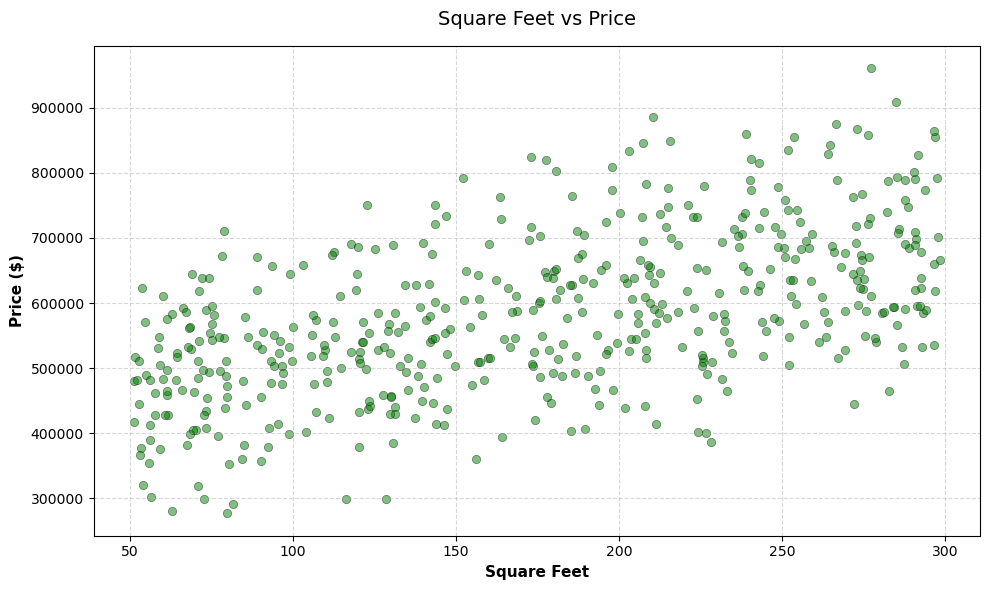

In [5]:
# Task 2.2. Visualise the relationship between Square Feet and Price using a scatter plot

# Import visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the overall dimensions (width, height) of the figure canvas
plt.figure(figsize=(10, 6))

# Generate a scatter plot using Seaborn's direct DataFrame integration
sns.scatterplot(
    data=df_house_price,  # Specifies the pandas DataFrame containing data
    x="Square_Feet",      # Specifies the column for the horizontal (x) axis
    y="Price",            # Specifies the column for the vertical (y) axis
    alpha=0.5,            # Transparency to handle overlapping points
    color="green",        # Color of the data markers
    edgecolors="k",       # Black border around markers for better contrast
)

# Customize the chart title and axis labels
plt.title("Square Feet vs Price", fontsize=14, pad=15)
plt.xlabel("Square Feet", fontsize=11, fontweight="bold")
plt.ylabel("Price ($)", fontsize=11, fontweight="bold")

# Add a subtle grid to make data reading easier
plt.grid(True, linestyle="--", alpha=0.5)

# Automatically adjust subplot parameters to fit the figure area cleanly
plt.tight_layout()

# Render and display the plot
plt.show()

**Square Feet vs Price (scatter plot):** There is a moderate positive relationship between house size and price, so larger houses generally cost more. However, the wide spread of points shows that size alone does not determine price.

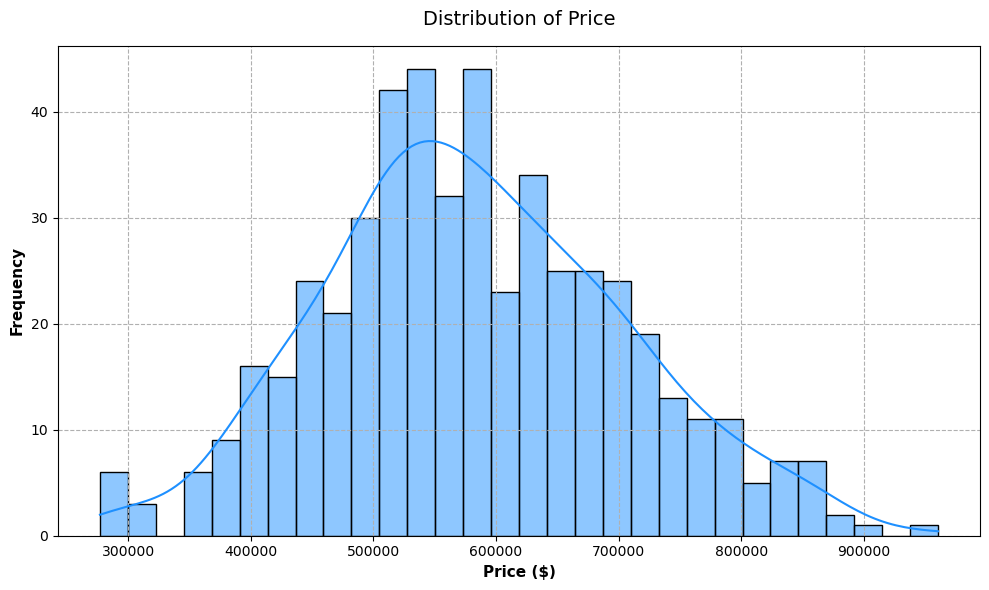

In [6]:
# Task 2.3. Visualise the distribution of the Price variable using a histogram

# Import required visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the dimensions (width, height) of the figure canvas
plt.figure(figsize=(10, 6))

# Generate the histogram with a Kernel Density Estimate (KDE) curve
sns.histplot(
    df_house_price["Price"], bins=30, kde=True, color="dodgerblue", edgecolors="k"
)
# bins = Number of bins to divide the data into
# kde = Overlay a smooth probability density curve
# color = Color of the histogram bars
# edgecolors = Black borders around bars for crisp visual separation

plt.title("Distribution of Price", fontsize=14, pad=15)
plt.xlabel("Price ($)", fontsize=11, fontweight="bold")
plt.ylabel("Frequency", fontsize=11, fontweight="bold")
plt.grid(True, linestyle="--")

plt.tight_layout()
plt.show()

**Distribution of Price (histogram):** Price is roughly bellshaped and fairly symmetric, centred at around $550k to $600k, with prices ranging from about $277k to $961k. There are no extreme outliers, which suits a linear regression model.


In [7]:
# Task 2.4: Compute correlation matrix

# Calculate the correlation matrix for all numerical columns in the DataFrame
corr_matrix = df_house_price.corr()

# Display the correlation matrix
print(corr_matrix)

                    Square_Feet  Num_Bedrooms  Num_Bathrooms  Num_Floors  \
Square_Feet            1.000000     -0.049918      -0.001667    0.056873   
Num_Bedrooms          -0.049918      1.000000      -0.056808    0.009088   
Num_Bathrooms         -0.001667     -0.056808       1.000000   -0.040895   
Num_Floors             0.056873      0.009088      -0.040895    1.000000   
Garage_Size           -0.051598     -0.065481       0.055707   -0.082763   
Location_Score        -0.035270     -0.000357      -0.013855    0.019928   
Distance_to_Center     0.093080      0.040511      -0.082571    0.035164   
Price                  0.558604      0.563973       0.156689    0.177435   

                    Garage_Size  Location_Score  Distance_to_Center     Price  
Square_Feet           -0.051598       -0.035270            0.093080  0.558604  
Num_Bedrooms          -0.065481       -0.000357            0.040511  0.563973  
Num_Bathrooms          0.055707       -0.013855           -0.082571  0.1566

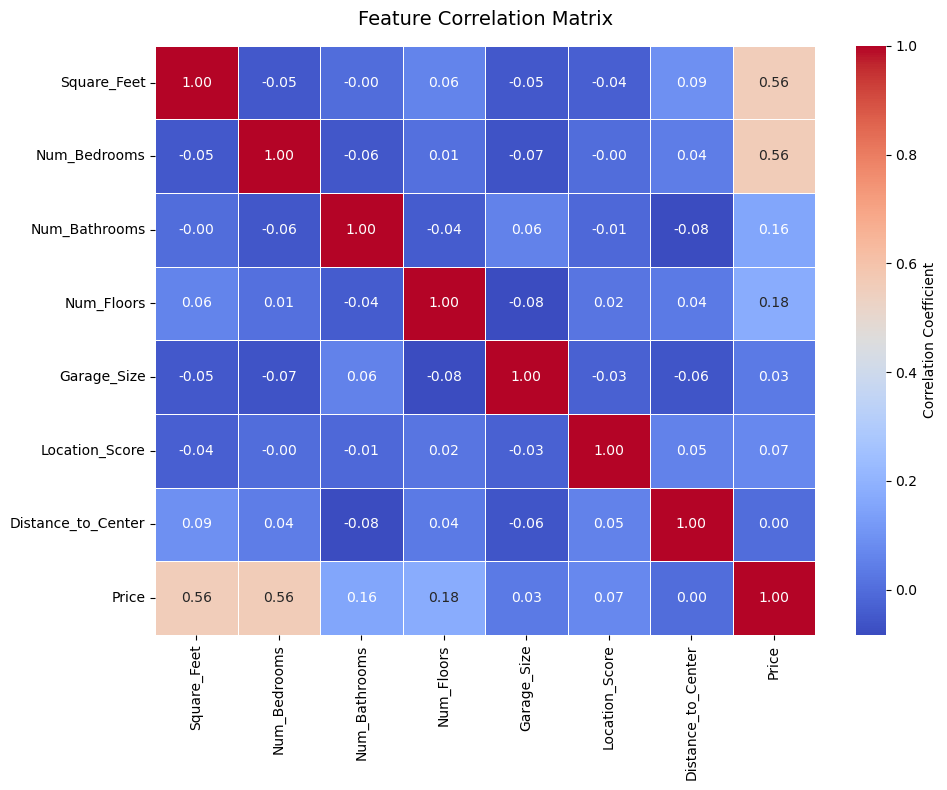

In [8]:
# Visualise correlation matrix using a heatmap

# Set the overall dimensions (width, height) for the heatmap figure canvas
plt.figure(figsize=(10, 8))

# Generate a heatmap to visualize the correlation matrix
sns.heatmap(
    corr_matrix,         # The correlation matrix data to plot
    annot=True,          # Display the actual correlation values inside each cell
    fmt=".2f",           # Format correlation values to 2 decimal places
    cmap="coolwarm",     # Color map (blue for negative correlation, red for positive)
    linewidths=0.5,      # Add thin white/gray borders between the cells
    cbar_kws={"label": "Correlation Coefficient"},         # Label for the color bar legend
)

# Customize the chart title and padding
plt.title("Feature Correlation Matrix", fontsize=14, pad=15)

# Automatically adjust layout elements to fit cleanly
plt.tight_layout()

# Display the heatmap
plt.show()

**Correlation matrix:** Square_Feet and Num_Bedrooms have the strongest correlation with Price (about 0.56 each), while Num_Floors (0.18) and Num_Bathrooms (0.16) are weak, and Location_Score, Garage_Size and Distance_to_Center are close to zero. The features do not overlap with each other so each one adds new information to the model.

## Step 3: Creating a Multiple Linear Regression (MLR) Model

In this step, we will use Multiple Linear Regression to predict the Price of the house based on the features. We will split the data into a training set and a testing set, fit the model, and evaluate its performance.

Task 3.1: Split the dataset into features (X) and target variable (y).

Task 3.2: Split the data into training (80%) and testing (20%) sets.

Task 3.3: Train the Multiple Linear Regression (MLR) model using the training data.

Task 3.4: Create a scatter plot comparing the actual prices and predicted prices for the test set.

Task 3.5: Evaluate the model using Root Mean Squared Error (RMSE) and interpret the results.

Task 3.6: Write 1–2 sentences explaining the insights from the visualisation.

In [9]:
# Task 3.1. Split the Data into Features and Target Split the dataset into features (X) and target variable (y)

# Select the features (inputs) the model will use to make predictions
# Drop 'Price', leaving every other columns as a feature in X
X = df_house_price.drop(columns=["Price"])

# Select the target variable (the answer/price we want the model to learn to predict)
y = df_house_price["Price"]

In [10]:
# Task 3.2. Split the Data into Training and Testing Sets Split the data into training (80%) and testing (20%) sets

# Import the function used to split data into training and testing sets
from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%) sets for machine learning
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Print the shape/size of the train and test sets to verify
print(f"Training Data: {X_train.shape}, Testing Data: {X_test.shape}")

Training Data: (400, 7), Testing Data: (100, 7)


In [11]:
# 3.3. Train the Multiple Linear Regression Model Train the Multiple Linear Regression (MLR) model using the training data

from sklearn.linear_model import LinearRegression

# Initialize the Linear Regression model
model_lr = LinearRegression()

# Train (fit) the model using the training data
model_lr.fit(X_train, y_train)

# Generate predictions on the testing dataset
y_pred_lr = model_lr.predict(X_test)

2026-11-09 06:45:19 [INFO] setting mlflow tracking uri to sds://api.fabric.microsoft.com/v1/workspaces/a98905a4-7ce4-43e6-91ba-fd215731856f/mlflow, change this environment variable if you want log to other places
🏃 View run honest_onion_bkfncv0h at: https://api.fabric.microsoft.com/v1/workspaces/a98905a4-7ce4-43e6-91ba-fd215731856f/mlflow/#/experiments/82e04236-d68a-4fce-b756-6d69eedcacc7/runs/754724f4-80e3-4965-9a05-666114db56ff
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/a98905a4-7ce4-43e6-91ba-fd215731856f/mlflow/#/experiments/82e04236-d68a-4fce-b756-6d69eedcacc7


In [12]:
# Create a DataFrame to compare actual prices side-by-side with model predictions
results_df = pd.DataFrame({"Actual Price": y_test, "Predicted Price (MLR)": y_pred_lr})

# Print the comparison table
print(results_df)

     Actual Price  Predicted Price (MLR)
361   591058.7089          525669.926934
73    667693.0003          668141.051861
374   532377.5802          467168.904743
155   478489.2990          498375.548472
104   730197.4806          691359.973840
..            ...                    ...
347   464849.9178          493645.118779
86    572360.6499          643248.170875
75    557752.8374          454235.083741
438   649930.0523          564489.566281
15    523527.9747          456453.859955

[100 rows x 2 columns]


**Close Predictions:**

    Row 347: Real price was $464,849, and MLR guessed $493,645 (a relatively close guess).

**Bigger Misses:**

    Row 75: Real price was $557,752, but MLR guessed $454,235 (underestimating by over $100,000).

    Row 86: Real price was $572,360, but MLR guessed $643,248 (overestimating by about $70,000).

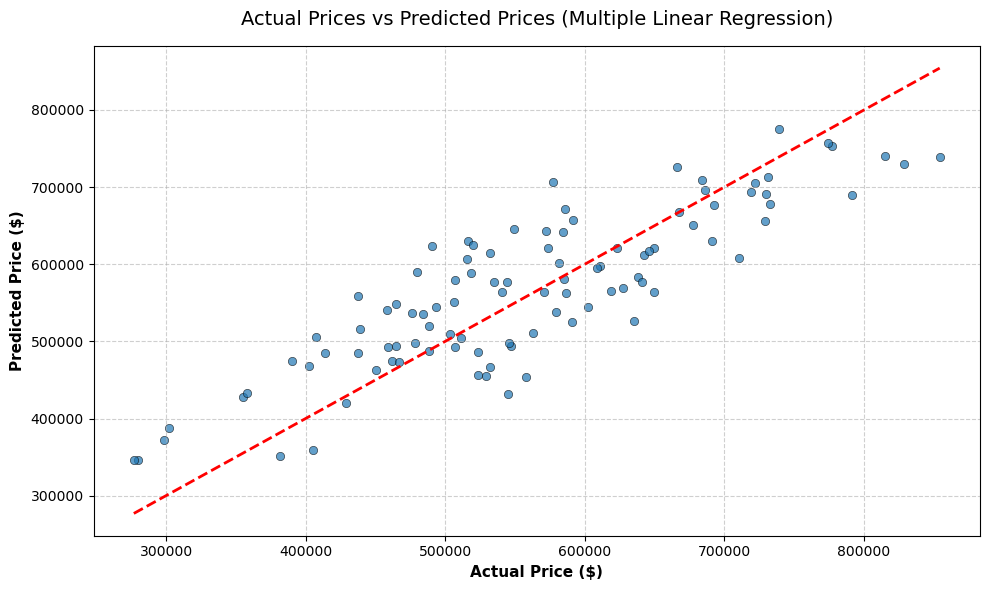

In [13]:
# Task 3.4. Visualise the Predicted vs Actual Prices Create a scatter plot comparing the actual prices and
# predicted prices for the test set

import matplotlib.pyplot as plt # Imports the core plotting library
import seaborn as sns # Imports Seaborn for enhanced visualizations

# Set the size of the graph figure (8 inches wide by 6 inches tall)
plt.figure(figsize=(10, 6))

# Create a scatter plot showing Actual Prices vs Predicted Prices
sns.scatterplot(data=results_df, x="Actual Price", y="Predicted Price (MLR)", alpha=0.7, edgecolors="k")

# Draw a red dashed diagonal line (where predictions perfectly match actuals) for reference
plt.plot(
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    [results_df["Actual Price"].min(), results_df["Actual Price"].max()],
    color="red",
    linestyle="--",
    lw=2,
)

# Add a soft gray, dashed background grid to make the chart easier to read
plt.grid(axis="both", linestyle="--", alpha=0.6)

# Add labels for the axes and a title to the chart
plt.xlabel("Actual Price ($)", fontsize=11, fontweight="bold")
plt.ylabel("Predicted Price ($)", fontsize=11, fontweight="bold")
plt.title("Actual Prices vs Predicted Prices (Multiple Linear Regression)", fontsize=14, pad=15)

# Automatically adjust plot spacing so labels and titles don't get cut off
plt.tight_layout()

# Display the final plot
plt.show()

**Key Takeaways from the MLR Plot**
    
    General Trend: The blue dots generally move upward along with the red reference line, meaning the model successfully learns the basic rule that bigger or better houses cost more money.

    Underestimating High-End Homes: Look at the right side of the plot (houses priced above $700,000). Nearly all the blue dots sit below the red line. This means the model is consistently failing to capture the full value of expensive luxury homes, guessing numbers that are too low.

    Overestimating Budget Homes: Conversely, on the far left side (houses under $400,000), the dots sit mostly above the red line. This shows the model tends to guess prices that are higher than what cheap homes actually sold for.

    The "Pull" Toward the Middle: Because a linear regression model relies on a straight line, it tends to squeeze predictions toward the average center of the data. It struggles when it encounters properties that are exceptionally cheap or exceptionally expensive.


In [14]:
# Task 3.5. Evaluate the Model
# We evaluate model performance by calculating the Root Mean Squared Error(RMSE).

# Import NumPy for mathematical operations (like square root)
import numpy as np

# Import Mean Squared Error to measure how far off the model's predictions are
from sklearn.metrics import mean_squared_error

# Calculate Root Mean Squared Error (RMSE) to measure prediction accuracy (lower is better)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))

# Print the final error score
print(f"Root Mean Squared Error (RMSE) for MLR: {rmse_lr}")

Root Mean Squared Error (RMSE) for MLR: 63952.37599755184


    Result: RMSE = $63,952.38

    Interpretation: On average, the model's price predictions deviate from the actual house sale prices by about $63,952.38. Lower RMSE values indicate better predictive accuracy.

    Task 3.6. Insights from the Visualization

    Insight: The scatter plot shows that the predicted prices closely track the ideal y = x diagonal line, indicating the model successfully captures general pricing trends across the dataset. However, the wider spread at extreme ends suggests the model tends to slightly overestimate lower-priced homes and underestimate higher-priced properties.


## Step 4: Compare with Random Forest Regressor

Task 4.1: Train a Random Forest Regressor model and evaluate its performance.

Task 4.2: Create a scatter plot comparing the actual prices and predicted prices for the Random Forest model.

Task 4.3: Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

In [15]:
# Task 4.1. Train a Random Forest Model Train a Random Forest Regressor model and evaluate its performance

# Import the Random Forest algorithm for building a collection of decision trees
from sklearn.ensemble import RandomForestRegressor

# Initialize the Random Forest model with 200 decision trees
model_rf = RandomForestRegressor(n_estimators=200, random_state=42)

# Train the Random Forest model using the training data
model_rf.fit(X_train, y_train)

# Generate predictions on the testing dataset
y_pred_rf = model_rf.predict(X_test)

🏃 View run zen_root_b1thtgc9 at: https://api.fabric.microsoft.com/v1/workspaces/a98905a4-7ce4-43e6-91ba-fd215731856f/mlflow/#/experiments/82e04236-d68a-4fce-b756-6d69eedcacc7/runs/9466b9b1-6d90-4b3f-a4cb-ccc857210d5f
🧪 View experiment at: https://api.fabric.microsoft.com/v1/workspaces/a98905a4-7ce4-43e6-91ba-fd215731856f/mlflow/#/experiments/82e04236-d68a-4fce-b756-6d69eedcacc7


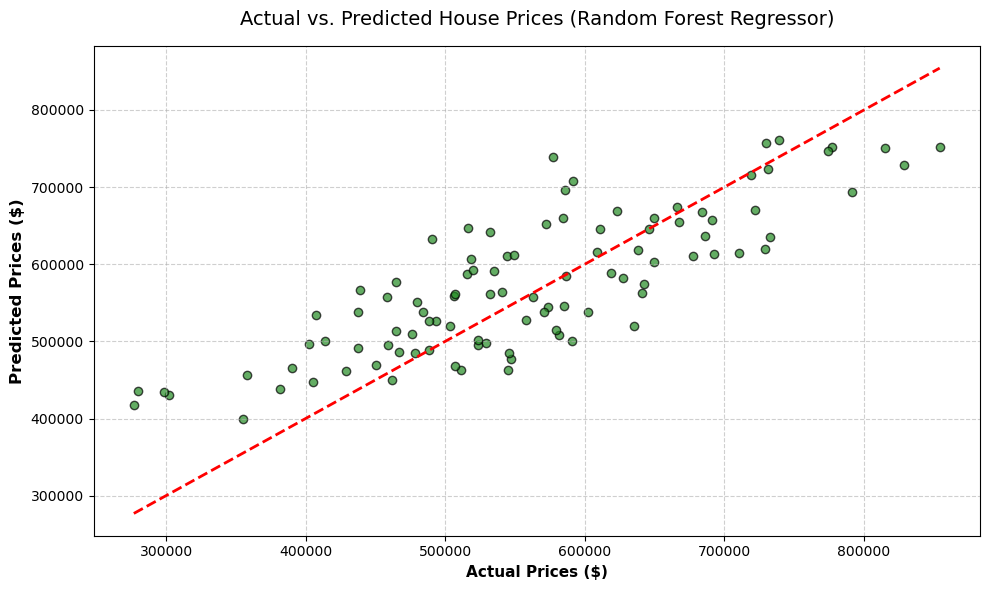

In [16]:
# Task 4.2: Visualise Actual vs Predicted Prices for Random Forest Create a scatter plot comparing
# the actual prices and predicted prices for the Random Forest model

import matplotlib.pyplot as plt

# Create a figure for the scatter plot
plt.figure(figsize=(10, 6))

# Plot actual vs. predicted test prices with green markers and black borders
plt.scatter(y_test, y_pred_rf, color="forestgreen", alpha=0.7, edgecolors="k")

# Add a 45-degree reference line (y = x) representing ideal predictions
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red", linestyle="--", lw=2)

# Style axis labels, title, and grid for readability
plt.xlabel("Actual Prices ($)", fontsize=11, fontweight="bold")
plt.ylabel("Predicted Prices ($)", fontsize=12, fontweight="bold")
plt.title("Actual vs. Predicted House Prices (Random Forest Regressor)", fontsize=14, pad=15)

plt.grid(True, linestyle="--", alpha=0.6)

# Adjust layout and display the plot
plt.tight_layout()
plt.show()

**Key Observations**
    
    - Strong Upward Trend: The green dots generally follow the direction of the red dashed line, which means the model successfully captures the overall relationship—higher real prices lead to higher predicted prices.

    - Underprediction on High-Value Homes: Notice how almost all the green dots on the far right (houses over $750,000) sit below the red line. This means the model tends to underestimate the price of expensive luxury houses.

    - Overprediction on Low-Value Homes: Conversely, green dots on the far left (houses under $400,000) mostly sit above the red line, meaning the model tends to overestimate cheaper homes.

    - Mid-Range Spread ($500k – $650k): In the middle price range, the points are clustered fairly tightly around the red line, showing that the model performs best on average-priced homes.

In [17]:
# Create a DataFrame to compare actual prices side-by-side with Random Forest predictions
results_df_rf = pd.DataFrame(
    {"Actual Price": y_test, "Predicted Price (Random Forest)": y_pred_rf}
)

# Print the first 5 rows of the comparison table
print(results_df_rf.head())

# Calculate the Root Mean Squared Error (RMSE) to measure accuracy (lower is better)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

# Print the final error score for the Random Forest model
print(f"Root Mean Squared Error (RMSE) for Random Forest: {rmse_rf}")

     Actual Price  Predicted Price (Random Forest)
361   591058.7089                    500627.243247
73    667693.0003                    654256.956307
374   532377.5802                    561434.354749
155   478489.2990                    484593.849958
104   730197.4806                    757536.282477
Root Mean Squared Error (RMSE) for Random Forest: 72013.1303207925


**Key Takeaways**

    General Trend Tracking: The model is capturing the overall scale and direction of house prices well. Some individual predictions are remarkably close (such as Row 73, where the prediction is within $13,000 of the actual price).

**Variance in Accuracy**

    Performance varies by property. While certain predictions have low error, others (like Row 361) show a gap of roughly $90,000, indicating that the model occasionally struggles with specific outliers or complex property features.

**Overall Error (RMSE)** An RMSE of $72,013.13 means that, on average, the model's price predictions deviate from the true market value by about $72K.

Display a Table with Actual vs Predicted Prices for all models

In [18]:
# Combine actual prices and both models' predictions into a single comparison table
results_df = pd.DataFrame(
    {
        "Actual Price": y_test,
        "Predicted Price (MLR)": y_pred_lr,
        "Predicted Price (Random Forest)": y_pred_rf,
    }
)

# Print the first 5 rows of the combined table to compare them side-by-side
print(results_df.head())

     Actual Price  Predicted Price (MLR)  Predicted Price (Random Forest)
361   591058.7089          525669.926934                    500627.243247
73    667693.0003          668141.051861                    654256.956307
374   532377.5802          467168.904743                    561434.354749
155   478489.2990          498375.548472                    484593.849958
104   730197.4806          691359.973840                    757536.282477


**MLR's Highs and Lows:**

    On Row 73, the Multiple Linear Regression model is astonishingly accurate—off by less than $500 ($668,141 vs. $667,693).

    However, on other rows like Row 374, MLR misses by a larger margin ($467,168 vs. $532,377).


**Random Forest's Consistency:**

    Random Forest tends to stay within a closer, more stable band around the actual values for most of these specific rows (such as Rows 155, 374, and 104).

In [19]:
# Task 4.3: Model Comparison Compare the RMSE values of both the MLR and Random Forest models. Which model performs better?

# Print the final RMSE scores for both models
print(f"RMSE for MLR: {rmse_lr}")
print(f"RMSE for Random Forest: {rmse_rf}")

# Compare the error scores (lower RMSE means a better, more accurate model)
if rmse_lr < rmse_rf:
    print("The Multiple Linear Regression model performs better based on RMSE.")
else:
    print("The Random Forest model perfoms better based on RMSE.")

RMSE for MLR: 63952.37599755184
RMSE for Random Forest: 72013.1303207925
The Multiple Linear Regression model performs better based on RMSE.


**Final Model Comparison Summary**

    - Multiple Linear Regression (MLR) RMSE = $63,952.38

    - Random Forest RMSE = $72,013.13

**Conclusion:**

    The Multiple Linear Regression model performs better on this test set, achieving a lower Root Mean Squared Error than the Random Forest model. This indicates that the relationships on the housing dataset lean more heavily toward linear patterns, which the simpler linear model captures cleanly without the higher variance seen in the default tree ensemble.

## Step 5: Conclusion and Insights

Task 5.1: Insights and Recommendations

Based on the RMSE and visualisations, summarise which model performs better and why.

Discuss any improvements that could be made to both models.

**Step 5: Conclusion and Insights**

    Task 5.1: Insights and Recommendations

    Model Performance Summary:

    The Multiple Linear Regression (MLR) model performed better on this dataset, achieving a lower Root Mean Squared Error (MLR RMSE: $63,952.38 vs. Random Forest RMSE: $72,013.13).

    Why MLR Performed Better:

    The exploratory data analysis (EDA) showed strong linear relationships (especially between house size and price). Because the data naturally follows linear trends, the simpler Multiple Linear Regression model captured these patterns cleanly without the extra error introduced by the default tree ensemble.

    Simple Future Improvements:

    If we wanted to improve the models further in the future, we could:

    Test more variables: Try including or combining different features to see if any other combinations improve predictions.

    Adjust model settings: Experiment with changing the settings (hyperparameters) on the Random Forest model—such as limiting how deep the trees can grow (max_depth)—to see if it reduces errors.
